* Context Engineering
    * 결과물이 가공되지 않은 통계적 추측에서 정교하면서도 신뢰할 수 있고 완벽하게 정렬된 응답을 뱉도록 하는 일
    1. 수준 1: 기본 프롬프트
    2. 수준 2: 선형 컨텍스트
    3. 수준 3: 목표 지향적 컨텍스트
    4. 수준 4: 역할 기반 컨텍스트
    5. 수준 5: 의미역 - 문장 성분의 의미론적인 역할을 활용해서 계획을 정확하고 명확하게 세우는 과정 

* SRL
    * 선형 시퀀스를 구조로 파악하기 위한 의미역을 결정하는 언어학적 기법
    * 누가, 무엇을, 누구에게, 언제, 어디서, 왜 했는가라는 근본적인 질문에 답하는 것
    * 문장 성분의 의미역을 가려내는 과정

* 의미역
    * 서술어(predicate): 핵심 행동, 상태
    * 행동주(ARG0): 행동을 수행하는 개체
    * 피동주(ARG1): 동사에 영향을 받거나 행위의 대상
    * 수혜자(ARG2): 행동의 결과를 받는 개체, 피동주와 동일 할 수 있음
    * 논항 수식어(ARGM-): 맥락을 제공 | 핵심적인 행동에는 필수적이지 않음
    <br> 언제, 어디서, 왜, 어떻게

In [2]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch

In [11]:
def _plot_stemma(verb, srl_roles):
    """stemma 시각화를 위한 내부 보조 함수"""
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 10)
    ax.axis('off')

    verb_style = dict(boxstyle='round,pad=0.5', fc='lightblue', ec='b')
    role_style = dict(boxstyle='round,pad=0.5', fc='lightgreen', ec='g')

    # 동적 위치 지정
    verb_pos = (5, 8.5)
    ax.text(verb_pos[0], verb_pos[1], verb, ha="center", va="center", bbox=verb_style, fontsize=12)

    srl_items = list(srl_roles.items())
    num_roles = len(srl_items)
    x_positions = [10*(i+1) / (num_roles+1) for i in range(num_roles)] # list
    y_positions = 4.5

    # role, arrow, label
    for i, (role, text) in enumerate(srl_items):
        child_pos = (x_positions[i], y_positions)
        ax.text(child_pos[0], child_pos[1], text, ha="center", va="center", bbox=role_style, fontsize=10, wrap=True)

        # 화살표 그리기
        arrow = FancyArrowPatch(
            verb_pos, child_pos, arrowstyle='->', mutation_scale=20,
            shrinkA=5, shrinkB=15, color='gray'
        )
        ax.add_patch(arrow)

        # 레이블 추가
        label_pos = ((verb_pos[0] + child_pos[0]) / 2, (verb_pos[1] + child_pos[1]) / 2 + 0.5)
        ax.text(label_pos[0], label_pos[1], role, ha="center", va="center", fontsize=7.5,
            color='black', bbox=dict(boxstyle="square,pad=0.1", fc='white', ec='black')
        )

    fig.suptitle("The Semantic Bluepritn(Stemma Visualiation)", fontsize=16)
    plt.show()

In [7]:
def visualize_srl(verb, agent=None, patient=None, recipient=None, temporal=None, location=None, manner=None):
    """ 의미 청사진을 생성하고 stemma로 시각화 """
    srl_roles ={}
    if agent:
        srl_roles['ARG0'] = agent
    if patient:
        srl_roles['Patient(ARG1)'] = patient
    if recipient:
        srl_roles['Recipient(ARG2)'] = recipient
    if temporal:
        srl_roles['Temoral(ARGM-TMP)'] = temporal
    if location:
        srl_roles['Location(ARGM-LOC)'] = location
    if manner:
        srl_roles['Manner(ARGM-MNR)'] = manner

    if not srl_roles:
        print("최소 하나 이상의 역할이 필요합니다.")
        return
    
    _plot_stemma(verb, srl_roles)

Ex1: A complete action with multiple roles


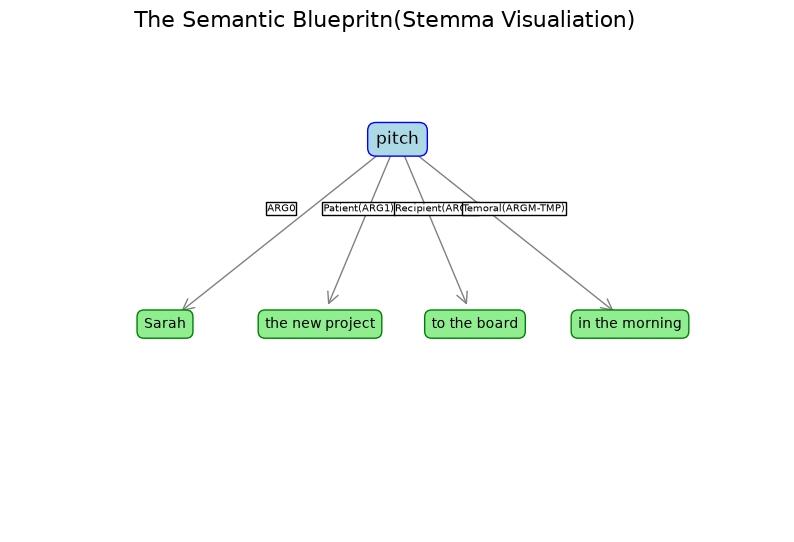

: 

In [ ]:
# Ex1: A complete action with multiple roles
print("Ex1: A complete action with multiple roles")
visualize_srl(
    verb="pitch",
    agent="Sarah",
    patient="the new project",
    recipient="to the board",
    temporal="in the morning"
)